# 🧡 TensorFlow + Keras Mastery — One Notebook to Rule Them All

A single, hands-on path from tensors to full training with Keras. Every section has a
**Concept**, a runnable **Demo**, and an **Exercise** with the solution right below.

**Three ideas that unlock TensorFlow:**
1. **Tensor** — an n-dimensional array (like NumPy) that runs on CPU/GPU. TF 2.x runs
   **eagerly** by default, so tensors evaluate immediately.
2. **`GradientTape`** — TF's autodiff: record operations on a tape, then ask for gradients.
3. **Keras** — the high-level API. Most of the time you `compile()` a model and call `fit()`;
   drop to a `GradientTape` loop only when you need full control.

All data here is tiny and synthetic, so every cell runs in seconds on CPU.

## Table of Contents
1. Setup, tensors & eager execution
2. Creating tensors & operations
3. The NumPy bridge
4. Variables & `GradientTape` (autodiff)
5. Reshaping & broadcasting
6. Models I — the Sequential API
7. Models II — the Functional API
8. Models III — subclassing `keras.Model`
9. Common layers
10. Activations, losses, optimizers, metrics
11. `compile` + `fit`: the Keras training loop
12. `tf.data` input pipelines
13. Regression end-to-end
14. Classification (MLP) with validation curves
15. A small convolutional network
16. Custom training loop with `GradientTape`
17. Callbacks (early stopping, checkpoints)
18. Saving & loading models
19. Evaluation & inference (`predict`)
20. 🏆 Capstone — end-to-end classification

## 1. Setup, Tensors & Eager Execution

We quiet TensorFlow's startup logging, then confirm the version and available devices.
A tensor has a `shape`, a `dtype`, and (because of eager mode) an immediately-available value.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide INFO/WARNING spam (set before import)

import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

tf.get_logger().setLevel("ERROR")
keras.utils.set_random_seed(0)              # seeds python, numpy, and tf at once

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)
print("eager mode:", tf.executing_eagerly())
print("GPUs      :", tf.config.list_physical_devices("GPU") or "none (running on CPU)")

t = tf.constant([[1.0, 2.0, 3.0],
                 [4.0, 5.0, 6.0]])
print(t)
print("shape:", t.shape, "| dtype:", t.dtype)
print("as numpy:\n", t.numpy())             # eager tensors convert instantly

TensorFlow: 2.21.0
Keras     : 3.15.1
eager mode: True
GPUs      : none (running on CPU)
tf.Tensor(
[[1. 2. 3.]
 [4. 5. 6.]], shape=(2, 3), dtype=float32)
shape: (2, 3) | dtype: <dtype: 'float32'>
as numpy:
 [[1. 2. 3.]
 [4. 5. 6.]]


**Exercise 1** — Create a constant 3×2 float tensor of your choice and print its shape, dtype, and rank (`tf.rank`).

In [2]:
# Your turn:

In [3]:
# Solution
x = tf.constant([[1., 2.], [3., 4.], [5., 6.]])
print("shape:", x.shape, "| dtype:", x.dtype, "| rank:", tf.rank(x).numpy())

shape: (3, 2) | dtype: <dtype: 'float32'> | rank: 2


## 2. Creating Tensors & Operations

Constructors mirror NumPy. Math ops are element-wise; `@`/`tf.matmul` is matrix multiply.

In [4]:
print(tf.zeros((2, 3)))
print(tf.ones((2, 3)))
print(tf.range(0, 10, 2))
print(tf.linspace(0.0, 1.0, 5))
print(tf.eye(3))
print(tf.random.normal((2, 2), seed=1))
print(tf.random.uniform((2, 2)))
print(tf.fill((2, 2), 7))

a = tf.constant([1.0, 2.0, 3.0]); b = tf.constant([4.0, 5.0, 6.0])
print("add:", (a + b).numpy(), "| mul:", (a * b).numpy())
print("reduce_sum:", tf.reduce_sum(a).numpy())
print("reduce_mean axis=0:", tf.reduce_mean(tf.reshape(tf.range(6.0), (2, 3)), axis=0).numpy())
A = tf.random.normal((2, 3)); B = tf.random.normal((3, 4))
print("matmul shape:", (A @ B).shape)

tf.Tensor(
[[0. 0. 0.]
 [0. 0. 0.]], shape=(2, 3), dtype=float32)
tf.Tensor(
[[1. 1. 1.]
 [1. 1. 1.]], shape=(2, 3), dtype=float32)
tf.Tensor([0 2 4 6 8], shape=(5,), dtype=int32)
tf.Tensor([0.   0.25 0.5  0.75 1.  ], shape=(5,), dtype=float32)
tf.Tensor(
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]], shape=(3, 3), dtype=float32)
tf.Tensor(
[[ 0.6803454   0.87778246]
 [-0.64773595  1.6695901 ]], shape=(2, 2), dtype=float32)
tf.Tensor(
[[0.29197514 0.20656645]
 [0.53539073 0.5612575 ]], shape=(2, 2), dtype=float32)
tf.Tensor(
[[7 7]
 [7 7]], shape=(2, 2), dtype=int32)
add: [5. 7. 9.] | mul: [ 4. 10. 18.]
reduce_sum: 6.0
reduce_mean axis=0: [1.5 2.5 3.5]
matmul shape: (2, 4)


**Exercise 2** — Build a 3×3 identity tensor and a 3×3 normal-noise tensor (seed 2), add them, and print the result's column sums with `tf.reduce_sum(..., axis=0)`.

In [5]:
# Your turn:

In [6]:
# Solution
I = tf.eye(3)
noise = tf.random.normal((3, 3), seed=2)
s = tf.reduce_sum(I + noise, axis=0)
print(s.numpy())

[-1.034914   3.5084643  1.660626 ]


## 3. The NumPy Bridge

TF ops accept NumPy arrays, and `.numpy()` converts back. Interop is seamless.

In [7]:
arr = np.array([[1.0, 2.0], [3.0, 4.0]])
t = tf.constant(arr)                 # numpy -> tensor
print("tensor:\n", t)
print("sqrt via tf:\n", tf.sqrt(t).numpy())   # tensor -> numpy

# TF ops even accept raw numpy directly
print("mean of a numpy array via tf:", tf.reduce_mean(np.arange(10.0)).numpy())

tensor:
 tf.Tensor(
[[1. 2.]
 [3. 4.]], shape=(2, 2), dtype=float64)
sqrt via tf:
 [[1.         1.41421356]
 [1.73205081 2.        ]]
mean of a numpy array via tf: 4.5


**Exercise 3** — Convert a NumPy `arange(1, 13)` reshaped to (3, 4) into a tensor, then compute its per-row maximum with `tf.reduce_max(..., axis=1)`.

In [8]:
# Your turn:

In [9]:
# Solution
m = tf.constant(np.arange(1, 13).reshape(3, 4))
print(tf.reduce_max(m, axis=1).numpy())   # [ 4  8 12]

[ 4  8 12]


## 4. Variables & `GradientTape` (Autodiff)

- `tf.Variable` holds trainable state (weights).
- `tf.GradientTape` records operations; `tape.gradient(loss, vars)` returns the derivatives.

In [10]:
# Simplest case: y = x^2, dy/dx = 2x at x=3
x = tf.Variable(3.0)
with tf.GradientTape() as tape:
    y = x ** 2
print("dy/dx:", tape.gradient(y, x).numpy())   # 6.0

# A tiny linear layer, computing gradients of a loss
tf.random.set_seed(0)
X = tf.random.normal((4, 3))
W = tf.Variable(tf.random.normal((3, 1)))
b = tf.Variable(tf.zeros((1,)))
target = tf.random.normal((4, 1))

with tf.GradientTape() as tape:
    pred = X @ W + b
    loss = tf.reduce_mean((pred - target) ** 2)
dW, db = tape.gradient(loss, [W, b])
print("loss:", loss.numpy())
print("dL/dW:\n", dW.numpy())
print("dL/db:", db.numpy())

dy/dx: 6.0
loss: 4.1537256
dL/dW:
 [[ 3.5401888]
 [ 2.1869354]
 [-0.8810536]]
dL/db: [1.4313773]


**Exercise 4** — Let `f(x) = 3x³ + 2x` at x=2 (analytic derivative 9x²+2 = 38). Use `GradientTape` to get f and df/dx.

In [11]:
# Your turn:

In [12]:
# Solution
x = tf.Variable(2.0)
with tf.GradientTape() as tape:
    f = 3 * x ** 3 + 2 * x
print("f:", f.numpy(), "| df/dx:", tape.gradient(f, x).numpy())   # 28.0, 38.0

f: 28.0 | df/dx: 38.0


## 5. Reshaping & Broadcasting

`tf.reshape`, `tf.transpose`, `tf.expand_dims`, `tf.squeeze`. Broadcasting follows NumPy rules.

In [13]:
x = tf.range(12)
print(tf.reshape(x, (3, 4)))
print(tf.reshape(x, (2, -1)).shape)          # -1 inferred
g = tf.reshape(tf.range(6), (2, 3))
print("transpose:\n", tf.transpose(g))
print("expand_dims:", tf.expand_dims(g, 0).shape)    # (1,2,3)
print("squeeze:", tf.squeeze(tf.ones((1, 3, 1))).shape)  # (3,)

# Broadcasting: (2,3) + (3,) and + (2,1)
m = tf.reshape(tf.range(6.0), (2, 3))
print((m + tf.constant([10., 20., 30.])).numpy())
print((m + tf.constant([[100.], [200.]])).numpy())

tf.Tensor(
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]], shape=(3, 4), dtype=int32)
(2, 6)
transpose:
 tf.Tensor(
[[0 3]
 [1 4]
 [2 5]], shape=(3, 2), dtype=int32)
expand_dims: (1, 2, 3)
squeeze: (3,)
[[10. 21. 32.]
 [13. 24. 35.]]
[[100. 101. 102.]
 [203. 204. 205.]]


**Exercise 5** — Standardize the columns of a 5×3 normal tensor (subtract column mean, divide by column std) using `tf.math.reduce_mean`/`reduce_std` and broadcasting.

In [14]:
# Your turn:

In [15]:
# Solution
x = tf.random.normal((5, 3), seed=3)
mean = tf.reduce_mean(x, axis=0)
std = tf.math.reduce_std(x, axis=0)
xn = (x - mean) / std
print("col means ~0:", np.round(tf.reduce_mean(xn, axis=0).numpy(), 4))

col means ~0: [-0. -0. -0.]


## 6. Models I — The Sequential API

For a simple stack of layers, `keras.Sequential` is the quickest route.

In [16]:
model = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3),               # raw logits (no activation)
])
model.summary()

# Forward pass on a dummy batch
dummy = tf.random.normal((5, 4))
print("output shape:", model(dummy).shape)   # (5, 3)
print("trainable params:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

output shape: (5, 3)
trainable params: 243


**Exercise 6** — Build a Sequential model: input of 10 features → Dense(32, tanh) → Dense(1). Print its summary and run it on a batch of 8.

In [17]:
# Your turn:

In [18]:
# Solution
m = keras.Sequential([
    keras.layers.Input(shape=(10,)),
    keras.layers.Dense(32, activation="tanh"),
    keras.layers.Dense(1),
])
m.summary()
print(m(tf.random.normal((8, 10))).shape)   # (8, 1)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385 (1.50 KB)

 Trainable params: 385 (1.50 KB)

 Non-trainable params: 0 (0.00 B)

(8, 1)


## 7. Models II — The Functional API

For branching/merging architectures, wire layers as functions on tensors. More flexible than
Sequential; you explicitly connect inputs to outputs.

In [19]:
inputs = keras.Input(shape=(4,))
x = keras.layers.Dense(16, activation="relu")(inputs)
x = keras.layers.Dense(16, activation="relu")(x)
outputs = keras.layers.Dense(3)(x)
model = keras.Model(inputs=inputs, outputs=outputs, name="functional_mlp")
print("output:", model(tf.random.normal((5, 4))).shape)

# A two-input model, showing why Functional exists
in_a = keras.Input(shape=(4,), name="a")
in_b = keras.Input(shape=(2,), name="b")
merged = keras.layers.Concatenate()([in_a, in_b])
out = keras.layers.Dense(1)(merged)
multi = keras.Model([in_a, in_b], out)
print("two-input output:", multi([tf.random.normal((3, 4)), tf.random.normal((3, 2))]).shape)

output: (5, 3)
two-input output: (3, 1)


**Exercise 7** — Using the Functional API, build a model: input(8) → Dense(16, relu) → Dense(16, relu) → Dense(2). Confirm the output shape on a batch of 4.

In [20]:
# Your turn:

In [21]:
# Solution
inp = keras.Input(shape=(8,))
h = keras.layers.Dense(16, activation="relu")(inp)
h = keras.layers.Dense(16, activation="relu")(h)
out = keras.layers.Dense(2)(h)
model = keras.Model(inp, out)
print(model(tf.random.normal((4, 8))).shape)   # (4, 2)

(4, 2)


## 8. Models III — Subclassing `keras.Model`

For full control (dynamic logic in `call`), subclass `keras.Model` — the analogue of PyTorch's
`nn.Module`.

In [22]:
class MLP(keras.Model):
    def __init__(self, hidden, n_classes):
        super().__init__()
        self.d1 = keras.layers.Dense(hidden, activation="relu")
        self.d2 = keras.layers.Dense(hidden, activation="relu")
        self.out = keras.layers.Dense(n_classes)

    def call(self, x):
        return self.out(self.d2(self.d1(x)))

model = MLP(hidden=32, n_classes=3)
_ = model(tf.random.normal((5, 4)))   # build by calling once
model.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (5, 32)                │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (5, 32)                │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (5, 3)                 │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315 (5.14 KB)

 Trainable params: 1,315 (5.14 KB)

 Non-trainable params: 0 (0.00 B)

**Exercise 8** — Subclass `keras.Model` to build a regressor: two Dense(24, relu) layers then Dense(1). Build it with a (6, 5) batch and print the output shape.

In [23]:
# Your turn:

In [24]:
# Solution
class Reg(keras.Model):
    def __init__(self):
        super().__init__()
        self.h1 = keras.layers.Dense(24, activation="relu")
        self.h2 = keras.layers.Dense(24, activation="relu")
        self.out = keras.layers.Dense(1)
    def call(self, x):
        return self.out(self.h2(self.h1(x)))

r = Reg()
print(r(tf.random.normal((6, 5))).shape)   # (6, 1)

(6, 1)


## 9. Common Layers

In [25]:
batch = tf.random.normal((8, 16))
print("Dense       :", keras.layers.Dense(4)(batch).shape)
print("Dropout     :", keras.layers.Dropout(0.5)(batch, training=True).shape)
print("BatchNorm   :", keras.layers.BatchNormalization()(batch, training=True).shape)
print("LayerNorm   :", keras.layers.LayerNormalization()(batch).shape)

img = tf.random.normal((8, 32, 32, 3))   # NOTE: TF uses channels-LAST (N,H,W,C)
conv = keras.layers.Conv2D(6, kernel_size=3, padding="same", activation="relu")
print("Conv2D      :", conv(img).shape)                     # (8,32,32,6)
print("MaxPool2D   :", keras.layers.MaxPooling2D(2)(conv(img)).shape)   # (8,16,16,6)
print("Flatten     :", keras.layers.Flatten()(conv(img)).shape)
print("Embedding   :", keras.layers.Embedding(100, 8)(tf.random.uniform((4, 5), 0, 100, tf.int32)).shape)

Dense       : (8, 4)
Dropout     : (8, 16)
BatchNorm   : (8, 16)


LayerNorm   : (8, 16)
Conv2D      : (8, 32, 32, 6)


MaxPool2D   : (8, 16, 16, 6)
Flatten     : (8, 6144)


Embedding   : (4, 5, 8)


**Exercise 9** — Pass a batch of 4 grayscale 28×28 images (shape `(4, 28, 28, 1)`) through a `Conv2D(8, 3, padding='same')` then `MaxPooling2D(2)`, and print the output shape.

In [26]:
# Your turn:

In [27]:
# Solution
imgs = tf.random.normal((4, 28, 28, 1))
c = keras.layers.Conv2D(8, 3, padding="same")(imgs)
p = keras.layers.MaxPooling2D(2)(c)
print(p.shape)   # (4, 14, 14, 8)

(4, 14, 14, 8)


## 10. Activations, Losses, Optimizers, Metrics

Keras provides all the standard pieces as objects or string names.
**Key rule:** for classification, keep the final layer as raw logits and pass
`from_logits=True` to the loss — it's more numerically stable than a softmax layer.

In [28]:
# Losses
mse = keras.losses.MeanSquaredError()
print("MSE:", mse(tf.constant([[1.0], [2.0]]), tf.constant([[1.5], [1.0]])).numpy())

scce = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
logits = tf.constant([[2.0, 0.5, 0.1], [0.1, 0.2, 3.0]])
labels = tf.constant([0, 2])
print("SparseCCE:", scce(labels, logits).numpy())

# Optimizers
for opt in [keras.optimizers.Adam(0.01), keras.optimizers.SGD(0.1, momentum=0.9)]:
    print("optimizer:", opt.__class__.__name__, "| lr:", opt.learning_rate.numpy())

# Metrics are stateful: update then read
acc = keras.metrics.SparseCategoricalAccuracy()
acc.update_state(labels, logits)
print("accuracy:", acc.result().numpy())

MSE: 0.625
SparseCCE: 0.2131901


optimizer: Adam | lr: 0.01
optimizer: SGD | lr: 0.1


accuracy: 1.0


**Exercise 10** — Compute the sparse categorical cross-entropy for 3 samples over 4 classes (random logits, seed via `tf.random.set_seed(0)`) with labels `[2, 0, 3]`.

In [29]:
# Your turn:

In [30]:
# Solution
tf.random.set_seed(0)
logits = tf.random.normal((3, 4))
labels = tf.constant([2, 0, 3])
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)(labels, logits)
print(loss.numpy())

2.4767148


## 11. `compile` + `fit`: The Keras Training Loop

This is the high-level workflow you'll use most:
```
model.compile(optimizer=..., loss=..., metrics=[...])
history = model.fit(X, y, epochs=..., validation_split=...)
```
Keras handles batching, the gradient steps, and metric tracking for you.

learned: y = 1.974 x + 1.000   (true 2x + 1)


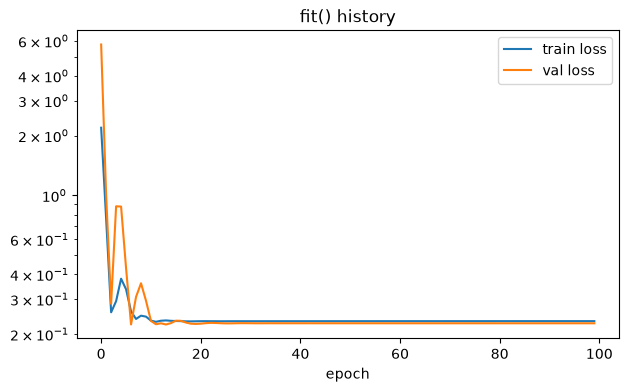

In [31]:
# Fit a line y = 2x + 1 from noisy data
rng = np.random.default_rng(0)
X = np.linspace(-3, 3, 200).reshape(-1, 1).astype("float32")
y = (2 * X + 1 + 0.5 * rng.normal(size=X.shape)).astype("float32")

model = keras.Sequential([keras.layers.Input((1,)), keras.layers.Dense(1)])
model.compile(optimizer=keras.optimizers.Adam(0.1), loss="mse", metrics=["mae"])
history = model.fit(X, y, epochs=100, verbose=0, validation_split=0.2)

w, b = model.layers[0].get_weights()
print(f"learned: y = {w[0,0]:.3f} x + {b[0]:.3f}   (true 2x + 1)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="train loss")
ax.plot(history.history["val_loss"], label="val loss")
ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.legend(); ax.set_title("fit() history")
plt.show()

**Exercise 11** — Fit `y = -3x + 2` from noisy data with `compile`/`fit` (80 epochs, 20% validation). Print the learned slope and intercept.

In [32]:
# Your turn:

In [33]:
# Solution
rng = np.random.default_rng(1)
X = np.linspace(-2, 2, 120).reshape(-1, 1).astype("float32")
y = (-3 * X + 2 + 0.3 * rng.normal(size=X.shape)).astype("float32")
m = keras.Sequential([keras.layers.Input((1,)), keras.layers.Dense(1)])
m.compile(optimizer=keras.optimizers.Adam(0.1), loss="mse")
m.fit(X, y, epochs=80, verbose=0, validation_split=0.2)
w, b = m.layers[0].get_weights()
print(f"slope {w[0,0]:.3f}, intercept {b[0]:.3f}  (true -3, 2)")

slope -3.013, intercept 1.976  (true -3, 2)


## 12. `tf.data` Input Pipelines

`tf.data.Dataset` builds efficient, shuffled, batched input pipelines that `fit` can consume
directly — the scalable way to feed data.

In [34]:
X = np.random.default_rng(0).normal(size=(100, 3)).astype("float32")
y = np.random.default_rng(1).integers(0, 2, 100)

ds = tf.data.Dataset.from_tensor_slices((X, y))
ds = ds.shuffle(buffer_size=100).batch(16)

print("number of batches:", ds.cardinality().numpy())
for xb, yb in ds.take(1):
    print("one batch:", xb.shape, yb.shape)

# Chainable transforms: map, filter, repeat, prefetch
scaled = ds.map(lambda xb, yb: (xb * 2.0, yb)).prefetch(tf.data.AUTOTUNE)
print("after map, first batch max ~2x:", float(tf.reduce_max(next(iter(scaled))[0])))

number of batches: 7
one batch: (16, 3) (16,)
after map, first batch max ~2x: 5.1048479080200195


**Exercise 12** — Build a `tf.data.Dataset` from 60 samples of 4 features, shuffle it, batch by 10, and print the number of batches.

In [35]:
# Your turn:

In [36]:
# Solution
X = np.random.default_rng(2).normal(size=(60, 4)).astype("float32")
y = np.random.default_rng(3).integers(0, 3, 60)
ds = tf.data.Dataset.from_tensor_slices((X, y)).shuffle(60).batch(10)
print("batches:", ds.cardinality().numpy())   # 6

batches: 6


## 13. Regression End-to-End

A small multi-feature regression with a multi-layer network, trained with `fit`.

final val MAE: 0.1734


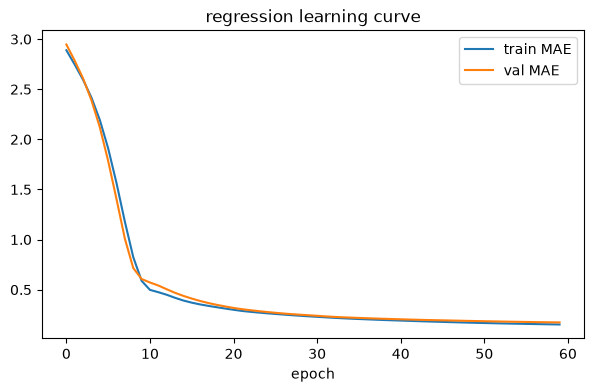

In [37]:
rng = np.random.default_rng(0)
n = 500
X = rng.normal(size=(n, 3)).astype("float32")
# true relationship + noise
y = (3 * X[:, 0] - 2 * X[:, 1] + 0.5 * X[:, 2] ** 2 + rng.normal(0, 0.1, n)).astype("float32").reshape(-1, 1)

model = keras.Sequential([
    keras.layers.Input((3,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
hist = model.fit(X, y, epochs=60, batch_size=32, validation_split=0.2, verbose=0)
print(f"final val MAE: {hist.history['val_mae'][-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist.history["mae"], label="train MAE")
ax.plot(hist.history["val_mae"], label="val MAE")
ax.legend(); ax.set_xlabel("epoch"); ax.set_title("regression learning curve")
plt.show()

**Exercise 13** — Report the model's predictions vs. true values for the first 5 samples (use `model.predict`).

In [38]:
# Your turn:

In [39]:
# Solution
preds = model.predict(X[:5], verbose=0).ravel()
print("pred:", np.round(preds, 3))
print("true:", np.round(y[:5].ravel(), 3))

pred: [ 0.996  1.412  2.297 -2.721 -5.821]
true: [ 0.967  1.393  2.144 -2.578 -5.843]


## 14. Classification (MLP) with Validation Curves

A full classifier on a synthetic 2-class problem (two concentric rings), with validation
tracking and accuracy/loss curves.

final val accuracy: 0.931


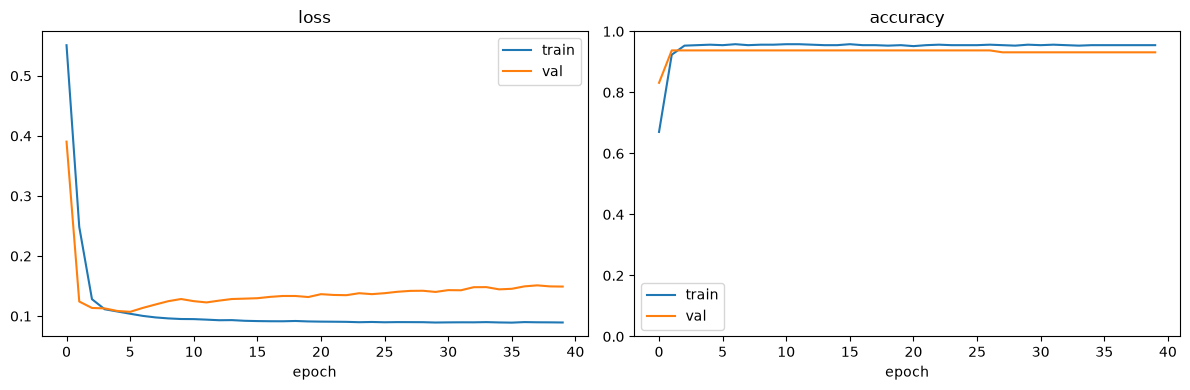

In [40]:
rng = np.random.default_rng(0)
n = 800
r = rng.uniform(0, 1, n)
theta = rng.uniform(0, 2 * np.pi, n)
label = (r > 0.5).astype("int32")
r_noisy = r + rng.normal(0, 0.05, n)
X = np.stack([r_noisy * np.cos(theta), r_noisy * np.sin(theta)], axis=1).astype("float32")

model = keras.Sequential([
    keras.layers.Input((2,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(2),            # logits
])
model.compile(optimizer=keras.optimizers.Adam(0.01),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
hist = model.fit(X, label, epochs=40, batch_size=32, validation_split=0.2, verbose=0)
print(f"final val accuracy: {hist.history['val_accuracy'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history["loss"], label="train"); axes[0].plot(hist.history["val_loss"], label="val")
axes[0].set_title("loss"); axes[0].legend(); axes[0].set_xlabel("epoch")
axes[1].plot(hist.history["accuracy"], label="train"); axes[1].plot(hist.history["val_accuracy"], label="val")
axes[1].set_title("accuracy"); axes[1].legend(); axes[1].set_ylim(0, 1); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Exercise 14** — Use `model.evaluate` to report the loss and accuracy on the full dataset (verbose=0).

In [41]:
# Your turn:

In [42]:
# Solution
loss, acc = model.evaluate(X, label, verbose=0)
print(f"loss {loss:.4f} | accuracy {acc:.3f}")

loss 0.1045 | accuracy 0.955


## 15. A Small Convolutional Network

Synthetic 8×8 single-channel images: class depends on a vertical vs. horizontal stripe.
Note TensorFlow's **channels-last** image format: `(batch, height, width, channels)`.

CNN validation accuracy: 1.000


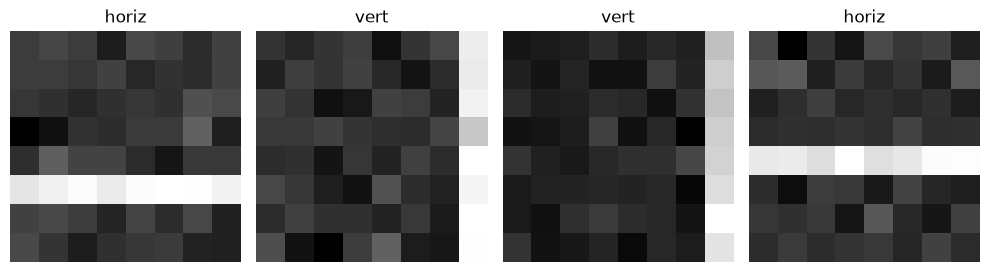

In [43]:
def make_stripe_images(n, seed):
    rng = np.random.default_rng(seed)
    imgs = rng.normal(0, 0.3, (n, 8, 8, 1)).astype("float32")   # channels-last
    labels = rng.integers(0, 2, n).astype("int32")
    for i, lab in enumerate(labels):
        k = rng.integers(0, 8)
        if lab == 0:
            imgs[i, :, k, 0] += 3.0          # vertical stripe
        else:
            imgs[i, k, :, 0] += 3.0          # horizontal stripe
    return imgs, labels

Xtr, ytr = make_stripe_images(800, 0)
Xva, yva = make_stripe_images(200, 1)

cnn = keras.Sequential([
    keras.layers.Input((8, 8, 1)),
    keras.layers.Conv2D(8, 3, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(2),
    keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(2),
    keras.layers.Flatten(),
    keras.layers.Dense(2),
])
cnn.compile(optimizer=keras.optimizers.Adam(0.01),
            loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=["accuracy"])
cnn.fit(Xtr, ytr, epochs=8, batch_size=32, verbose=0)
val_loss, val_acc = cnn.evaluate(Xva, yva, verbose=0)
print(f"CNN validation accuracy: {val_acc:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, img, lab in zip(axes, Xva[:4], yva[:4]):
    ax.imshow(img[:, :, 0], cmap="gray"); ax.set_title("vert" if lab == 0 else "horiz"); ax.axis("off")
plt.tight_layout(); plt.show()

**Exercise 15** — Print the CNN's total parameter count with `cnn.count_params()`, and its predicted classes for the first 5 validation images.

In [44]:
# Your turn:

In [45]:
# Solution
print("params:", cnn.count_params())
preds = cnn.predict(Xva[:5], verbose=0).argmax(axis=1)
print("pred:", preds, "| true:", yva[:5])

params: 1378
pred: [1 0 0 1 1] | true: [1 0 0 1 1]


## 16. Custom Training Loop with `GradientTape`

When `fit` isn't flexible enough, write the loop yourself. This is the low-level equivalent of
what `fit` does, and mirrors PyTorch's training loop.

final loss 0.0118 | accuracy 1.000


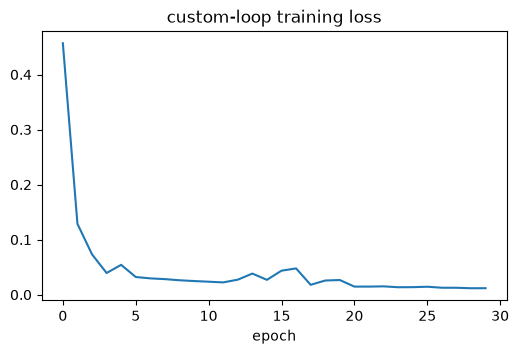

In [46]:
rng = np.random.default_rng(0)
X = rng.normal(size=(200, 2)).astype("float32")
y = ((X[:, 0] + X[:, 1]) > 0).astype("int32")       # simple linear boundary

model = keras.Sequential([keras.layers.Input((2,)),
                          keras.layers.Dense(16, activation="relu"),
                          keras.layers.Dense(2)])
optimizer = keras.optimizers.Adam(0.05)
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
ds = tf.data.Dataset.from_tensor_slices((X, y)).shuffle(200).batch(32)

losses = []
for epoch in range(30):
    epoch_loss = keras.metrics.Mean()
    for xb, yb in ds:
        with tf.GradientTape() as tape:
            logits = model(xb, training=True)
            loss = loss_fn(yb, logits)
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        epoch_loss.update_state(loss)
    losses.append(epoch_loss.result().numpy())

acc = keras.metrics.SparseCategoricalAccuracy()
acc.update_state(y, model(X))
print(f"final loss {losses[-1]:.4f} | accuracy {acc.result().numpy():.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(losses); ax.set_title("custom-loop training loss"); ax.set_xlabel("epoch")
plt.show()

**Exercise 16** — In a `GradientTape`, compute the gradient of `loss = reduce_mean((W @ x - 1)^2)` w.r.t. a `tf.Variable` `W` of shape (1, 3), with `x` a fixed (3, 1) tensor of ones.

In [47]:
# Your turn:

In [48]:
# Solution
W = tf.Variable(tf.random.normal((1, 3)))
x = tf.ones((3, 1))
with tf.GradientTape() as tape:
    loss = tf.reduce_mean((W @ x - 1.0) ** 2)
print("grad shape:", tape.gradient(loss, W).shape)   # (1, 3)

grad shape: (1, 3)


## 17. Callbacks

Callbacks hook into `fit` to automate behavior: stop early when validation stops improving,
save the best model, reduce the learning rate on a plateau.

In [49]:
rng = np.random.default_rng(0)
X = rng.normal(size=(400, 4)).astype("float32")
y = (X.sum(axis=1) > 0).astype("int32")

model = keras.Sequential([keras.layers.Input((4,)),
                          keras.layers.Dense(32, activation="relu"),
                          keras.layers.Dense(2)])
model.compile(optimizer="adam",
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                      restore_best_weights=True)
reduce = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3)

hist = model.fit(X, y, epochs=100, validation_split=0.2, verbose=0,
                 callbacks=[early, reduce])
print(f"stopped after {len(hist.history['loss'])} epochs (max was 100)")
print(f"best val accuracy: {max(hist.history['val_accuracy']):.3f}")

stopped after 100 epochs (max was 100)
best val accuracy: 0.988


**Exercise 17** — Re-run the fit above but with `EarlyStopping(patience=2)` and report how many epochs it ran.

In [50]:
# Your turn:

In [51]:
# Solution
model2 = keras.Sequential([keras.layers.Input((4,)),
                           keras.layers.Dense(32, activation="relu"),
                           keras.layers.Dense(2)])
model2.compile(optimizer="adam",
               loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
               metrics=["accuracy"])
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
h = model2.fit(X, y, epochs=100, validation_split=0.2, verbose=0, callbacks=[es])
print("epochs run:", len(h.history["loss"]))

epochs run: 100


## 18. Saving & Loading Models

Keras 3's native format is a single `.keras` file holding architecture + weights + optimizer
state. Load it back with `keras.models.load_model`. You can also save weights only.

In [52]:
import tempfile, os
tmp = tempfile.mkdtemp()
path = os.path.join(tmp, "model.keras")

model.save(path)
print("saved:", os.path.getsize(path), "bytes")

reloaded = keras.models.load_model(path)
# Verify identical predictions
same = np.array_equal(model.predict(X[:16], verbose=0).argmax(1),
                      reloaded.predict(X[:16], verbose=0).argmax(1))
print("reloaded matches original:", same)

# Weights-only round trip
wpath = os.path.join(tmp, "weights.weights.h5")
model.save_weights(wpath)
print("weights file:", os.path.getsize(wpath), "bytes")

saved: 23974 bytes
reloaded matches original: True
weights file: 21944 bytes


**Exercise 18** — Save the model to a `.keras` file, load it into a new variable, and confirm predictions match on the first 10 samples.

In [53]:
# Your turn:

In [54]:
# Solution
import tempfile, os
p = os.path.join(tempfile.mkdtemp(), "m.keras")
model.save(p)
m2 = keras.models.load_model(p)
print("match:", np.array_equal(model.predict(X[:10], verbose=0).argmax(1),
                               m2.predict(X[:10], verbose=0).argmax(1)))

match: True


## 19. Evaluation & Inference (`predict`)

- `model.evaluate` returns the loss and compiled metrics.
- `model.predict` returns raw outputs (here, logits) — apply `softmax` to get probabilities.

In [55]:
logits = model.predict(X[:5], verbose=0)
probs = tf.nn.softmax(logits, axis=1).numpy()
preds = probs.argmax(axis=1)

print("logits:\n", np.round(logits, 2))
print("probabilities:\n", np.round(probs, 3))
print("predicted:", preds)
print("true     :", y[:5])

loss, acc = model.evaluate(X, y, verbose=0)
print(f"full-set loss {loss:.4f} | accuracy {acc:.3f}")

logits:
 [[-2.82  2.51]
 [-5.75  4.99]
 [ 6.14 -5.96]
 [ 9.77 -9.03]
 [-2.11  1.81]]
probabilities:
 [[0.005 0.995]
 [0.    1.   ]
 [1.    0.   ]
 [1.    0.   ]
 [0.019 0.981]]
predicted: [1 1 0 0 1]
true     : [1 1 0 0 1]
full-set loss 0.0433 | accuracy 0.993


**Exercise 19** — For the first sample, print the predicted class and its confidence (max softmax probability).

In [56]:
# Your turn:

In [57]:
# Solution
p = tf.nn.softmax(model.predict(X[:1], verbose=0), axis=1).numpy()[0]
print(f"class {p.argmax()} with confidence {p.max():.3f}")

class 1 with confidence 0.995


## 20. 🏆 Capstone — End-to-End Classification

Put it all together. Try before peeking.

**Task.** Generate a 3-class dataset (three Gaussian blobs in 2-D). Build a Keras classifier,
train it with `fit` and an `EarlyStopping` callback, then produce: (1) loss and accuracy
curves, and (2) a scatter of the data colored by **predicted** class.

In [58]:
# Your turn:

epochs run: 80 | best val acc: 1.000


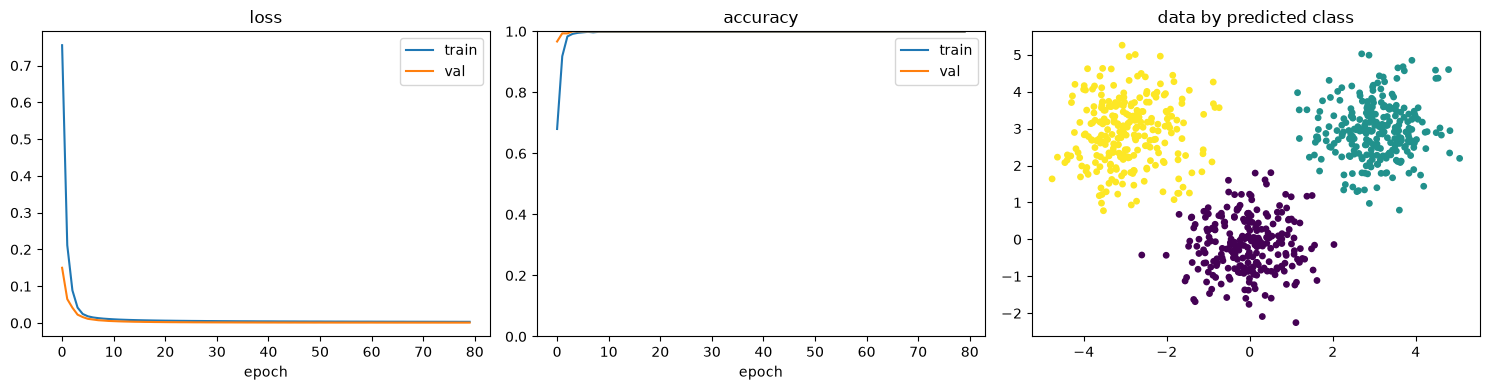

In [59]:
# Solution
rng = np.random.default_rng(7)
centers = np.array([[0, 0], [3, 3], [-3, 3]], dtype="float32")
per = 250
X = np.vstack([c + rng.normal(0, 0.8, (per, 2)) for c in centers]).astype("float32")
y = np.repeat(np.arange(3), per).astype("int32")

model = keras.Sequential([
    keras.layers.Input((2,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(3),
])
model.compile(optimizer=keras.optimizers.Adam(0.01),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
hist = model.fit(X, y, epochs=80, batch_size=32, validation_split=0.2, verbose=0, callbacks=[es])
print(f"epochs run: {len(hist.history['loss'])} | best val acc: {max(hist.history['val_accuracy']):.3f}")

pred = model.predict(X, verbose=0).argmax(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hist.history["loss"], label="train"); axes[0].plot(hist.history["val_loss"], label="val")
axes[0].set_title("loss"); axes[0].legend(); axes[0].set_xlabel("epoch")
axes[1].plot(hist.history["accuracy"], label="train"); axes[1].plot(hist.history["val_accuracy"], label="val")
axes[1].set_title("accuracy"); axes[1].legend(); axes[1].set_ylim(0, 1); axes[1].set_xlabel("epoch")
axes[2].scatter(X[:, 0], X[:, 1], c=pred, cmap="viridis", s=15)
axes[2].set_title("data by predicted class")
plt.tight_layout(); plt.show()

---
## 🎓 You Made It

If you can write the `compile`/`fit` workflow and a `GradientTape` loop from memory, you have the
core of TensorFlow + Keras. Where to go next:

- Swap synthetic data for real datasets via `keras.datasets` (MNIST, CIFAR-10) or `tf.data`.
- Add `TensorBoard` logging and learning-rate schedules.
- Explore transfer learning with `keras.applications` pretrained backbones.
- Compare this notebook with the PyTorch one — the concepts map almost one-to-one.

Delete the solution cells and redo the exercises in a week. Spaced repetition turns practice
into mastery.